# Merchant segmentation, and a ranking per segment

The firm can onboard at most 100 merchants. Ranked on a single list, those 100 are simply the
largest merchants, and the rest of the base is never examined. The spec therefore asks for three
to five segments, a ranking curated for each, and the top 10 merchants within each one.

**Merchants are segmented by how they perform**, using the six dimensions the group agreed on.
Section 5 checks that these segments are not just product categories in disguise.

| Output | What it is |
|---|---|
| `merchant_behaviour_segments` | every merchant in one of 4 segments |
| `top10_per_segment.csv` | the answer: top 10 in each segment |
| `merchant_segments` | supporting check only (see §5) |

In [9]:
from pathlib import Path
import sys
import pandas as pd

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "tables").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root containing data/tables/."
    )

PROJECT_ROOT = find_project_root()
PROCESSED = PROJECT_ROOT / "data" / "tables" / "processed"
SCRIPTS = PROJECT_ROOT / "scripts"

if str(SCRIPTS) not in sys.path:
    sys.path.insert(0, str(SCRIPTS))

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

behaviour = pd.read_parquet(PROCESSED / "merchant_behaviour_segments")
ranking = pd.read_parquet(PROCESSED / "merchant_ranking_v2.parquet")

print(f"{len(behaviour):,} merchants segmented")


4,026 merchants segmented


## 1. The six dimensions

Each merchant carries six numbers, built in `01_data_quality_eda.ipynb`:

| Dimension | Column | Meaning |
|---|---|---|
| Commercial value | `estimated_bnpl_revenue` | what the firm earns from them: their transaction value × take rate |
| Customer reach | `customer_penetration` | how much of the customer base they touch |
| Customer engagement | `transactions_per_customer` | how often a customer comes back |
| Growth | `log_value_growth` | recent three months against their earliest three |
| Historical activity | `active_month_ratio` | how many of the 19 months they actually traded in |
| Stability | `value_cv` | how much monthly takings jump around |

One caution carried through the whole notebook: `value_cv` is named for stability but measures
its opposite — a **high** value means erratic takings. It is renamed `volatility` in the code so
the sign cannot be misread.

## 2. Four segments

`scripts/segment_behaviour.py` clusters merchants on those six dimensions with k-means.

Two decisions are worth stating.

**Merchants are ranked on each dimension before clustering.** On the raw numbers, 76% of merchants
landed in a single cluster: revenue has a long right tail, so a few very large merchants stretch
the scale until everyone else looks identical. Percentile ranks spread them evenly, and "large
relative to the others" is what the comparison means anyway.

**k was chosen, not assumed.** Fitting k = 3, 4 and 5 gives silhouettes of 0.536, **0.589** and
0.528. Four wins, and its segments are the most evenly sized. The spec's 3-to-5 range is
satisfied by construction.

In [10]:
profile = (
    behaviour.groupby(["segment_id", "segment"])
    .agg(merchants=("merchant_abn", "size"),
         revenue=("commercial_value", "mean"),
         reach=("customer_reach", "mean"),
         engagement=("customer_engagement", "mean"),
         growth=("growth", "mean"),
         activity=("historical_activity", "mean"),
         volatility=("volatility", "mean"))
    .sort_values("merchants", ascending=False)
)
profile.round(3)

,,merchants,revenue,reach,engagement,growth,activity,volatility
segment_id,segment,,,,,,,
1,"high customer reach, low volatility",1616,49620.345,0.189,1.203,0.323,1.000,0.214
3,high growth,969,5623.876,0.012,1.006,0.619,0.989,0.466
2,low growth,888,5058.922,0.009,1.004,0.024,0.989,0.563
0,"low historical activity, high volatility",553,2017.715,0.001,1.000,0.266,0.581,1.391


### What each segment is

The cluster numbers are arbitrary; these names are ours, for the report.

| id | Name | Character |
|---|---|---|
| 1 | **Established** | wide customer base, steady takings — the large incumbents |
| 3 | **Rising** | mid-sized and growing |
| 2 | **Fading** | mid-sized and shrinking |
| 0 | **Intermittent** | trade in only some months, takings erratic |

Segments 2 and 3 are close in size and revenue and separate almost entirely on growth, which is
the useful distinction among mid-sized merchants: rising or fading.

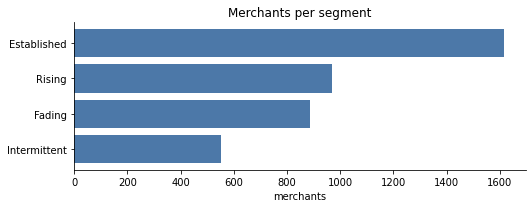

In [11]:
import matplotlib.pyplot as plt

NAMES = {1: "Established", 3: "Rising", 2: "Fading", 0: "Intermittent"}
counts = profile["merchants"]
labels = [f"{NAMES[i]}" for i, _ in counts.index]

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.barh(labels[::-1], counts.values[::-1], color="#4C78A8")
ax.set_xlabel("merchants")
ax.set_title("Merchants per segment")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Where the money is

Segment sizes say little on their own; revenue share is the number that matters.

In [12]:
joined = ranking.merge(behaviour[["merchant_abn", "segment_id", "segment"]], on="merchant_abn")

value = (
    joined.groupby("segment_id")
    .agg(merchants=("merchant_abn", "size"),
         bnpl_revenue=("estimated_bnpl_revenue", "sum"),
         avg_customers=("unique_customers", "mean"),
         txns_per_customer=("transactions_per_customer", "mean"))
)
value["merchant_share"] = value["merchants"] / value["merchants"].sum()
value["revenue_share"] = value["bnpl_revenue"] / value["bnpl_revenue"].sum()
value.index = [NAMES[i] for i in value.index]
value[["merchants", "merchant_share", "revenue_share", "avg_customers", "txns_per_customer"]].round(3)

,merchants,merchant_share,revenue_share,avg_customers,txns_per_customer
Intermittent,553,0.137,0.012,20.378,1.000
Established,1616,0.401,0.879,4551.129,1.203
Fading,888,0.221,0.049,225.200,1.004
Rising,969,0.241,0.060,277.534,1.006


**This table is the argument for segmenting at all.** One segment is 40% of merchants and holds
close to 90% of BNPL revenue. Rank every merchant on one list and the top 100 is drawn almost
entirely from it, leaving three quarters of the base unexamined.

Note also that repeat purchasing barely moves between segments (about 1.0 to 1.2 transactions per
customer). What separates merchants here is **how many customers they have**, not how often those
customers return.

## 4. A ranking inside each segment

The segment ranking uses the **same frozen v2 weights for every behavioural segment**.
What changes is the comparison set: each feature's percentile rank is recalculated relative to
merchants in the same segment before the v2 weights are applied.

This gives each segment a locally calibrated ranking without fitting a separate set of weights to
future realised revenue. In practical terms, an Established merchant is compared with other
Established merchants, while an Intermittent merchant is compared with other Intermittent
merchants, but the business priorities encoded by v2 stay consistent.

`scripts/top10_per_segment.py` implements this calculation and also retains two reference rankings:
the global v2 score and estimated historical BNPL revenue alone.


In [13]:
from top10_per_segment import SEGMENT_WEIGHTS, load, add_ranks

print("Frozen v2 weights used in every behavioural segment:")
pd.DataFrame(SEGMENT_WEIGHTS).rename(columns=NAMES).fillna(0).round(3)


Frozen v2 weights used in every behavioural segment:


,Established,Rising,Fading,Intermittent
estimated_bnpl_revenue,0.70,0.70,0.70,0.70
log_value_growth,0.08,0.08,0.08,0.08
transactions_per_customer,0.04,0.04,0.04,0.04
repeat_rate,0.03,0.03,0.03,0.03
stability,0.03,0.03,0.03,0.03
active_month_ratio,0.02,0.02,0.02,0.02
customer_spread,0.05,0.05,0.05,0.05
customer_income,0.03,0.03,0.03,0.03
customer_irsad,0.02,0.02,0.02,0.02


## 5. Are these segments just product categories?

If merchants of a kind behaved alike, grouping by what they sell would be simpler and this
segmentation would be redundant. `scripts/segment_merchants.py` builds that comparison: the
merchant tags reduce to 25 product categories, grouped into 5 (Technology, Home & Garden, Fashion,
Arts, Leisure). It exists for this check, not as a rival answer.

In [14]:
shop = pd.read_parquet(PROCESSED / "merchant_segments")[["merchant_abn", "segment"]]
shop = shop.rename(columns={"segment": "shop_type"})

cross = joined.merge(shop, on="merchant_abn", how="left")
share = pd.crosstab(cross["segment_id"], cross["shop_type"], normalize="index") * 100
share.index = [NAMES[i] for i in share.index]
share.round(1)


shop_type,"Arts, Media & Stationery",Fashion & Personal Care,Home & Garden,Leisure & Transport,Technology & Telecom
Intermittent,26.6,14.3,23.1,22.1,13.9
Established,21.5,19.6,20.4,13.0,25.6
Fading,24.3,19.4,20.7,15.2,20.4
Rising,23.8,20.0,19.1,16.8,20.2


Every behaviour segment holds roughly 13–26% of every product category. Performance is therefore
close to independent of what a merchant sells, and grouping by product would not have produced
these distinctions. The one visible tilt is that the least active merchants lean towards Arts and
away from Technology.

That settles the question: **behaviour is the segmentation, product category is the control.**

## 6. The top 10 in each segment

In [15]:
ranked = add_ranks(load())

for seg_id in [1, 3, 2, 0]:
    block = ranked[ranked.segment_id == seg_id]
    top = block.nsmallest(10, "rank_in_segment")
    print(f"\n=== {NAMES[seg_id]}  ({len(block):,} merchants) ===")
    print(
        top[["name", "segment_score", "estimated_bnpl_revenue", "unique_customers",
             "log_value_growth", "rank_overall"]]
        .to_string(index=False, float_format=lambda v: f"{v:,.2f}")
    )


=== Established  (1,616 merchants) ===
                         name  segment_score  estimated_bnpl_revenue  unique_customers  log_value_growth  rank_overall
Dignissim Maecenas Foundation          92.90              590,673.67             22326              0.36             1
            Leo In Consulting          92.57              581,136.25             24081              0.34             3
     Arcu Sed Eu Incorporated          92.57              432,454.15             18686              0.36             2
         Mauris Non Institute          92.37              544,064.20             23872              0.35             4
               Ornare Limited          92.28              548,590.52             17009              0.36             6
     Odio Phasellus Institute          92.24              536,062.14              8678              0.39             5
    Lobortis Ultrices Company          92.11              529,710.79             23816              0.34             7
        

In [16]:
rows = []
for seg_id in [1, 3, 2, 0]:
    block = ranked[ranked.segment_id == seg_id]
    picks = lambda col: set(block.nsmallest(10, col)["merchant_abn"])
    mine = picks("rank_in_segment")
    rows.append({
        "segment": NAMES[seg_id],
        "best merchant's rank on the overall list": int(block["rank_overall"].min()),
        "same picks as global v2": len(mine & picks("rank_in_segment_v2")),
        "same picks as past revenue": len(mine & picks("rank_in_segment_baseline")),
    })
pd.DataFrame(rows).set_index("segment")

,best merchant's rank on the overall list,same picks as global v2,same picks as past revenue
segment,,,
Established,1,9,8
Rising,780,5,1
Fading,1138,4,0
Intermittent,2094,4,1


**Two things to read here.**

The best merchant outside Established sits several hundred places down the overall ranking.
Without segmentation, those merchants would rarely appear in a shortlist.

The segment-specific score can also disagree substantially with the global v2 score and with
historical revenue alone. That difference comes from **recalculating percentile ranks within the
segment**, not from fitting separate future-informed weights. This is the main value of the
segmentation step: it surfaces strong merchants relative to peers with similar behaviour.


## 7. Limitations

1. **The global v2 weights were selected using the March–August development analysis.** They were
   frozen before the untouched September holdout; the segment ranking does not fit any additional
   weights from future outcomes.
2. **Historical revenue remains a strong benchmark.** The segment score adds growth, stability,
   engagement and customer-base context, so it should be justified as a broader onboarding
   framework rather than assumed to maximise revenue prediction.
3. **396 transacting merchants have no merchant metadata row.** Without a take rate they cannot be
   assigned an estimated BNPL revenue or included in the rankable population.
4. **Segments are balanced by merchant behaviour, not by commercial value.** A Top 10 merchant in
   Intermittent is not economically equivalent to a Top 10 merchant in Established.
5. **Some behavioural dimensions are missing for thin-history merchants.** The clustering script
   median-fills those dimensions and records a row-level `dims_imputed` flag.
